# NB-10 — CTC e CRNN (Cap. 2, §2.7 e §2.8)

> **Demonstração didática.** Base Washington (GW20, CIIR/UMass, uso não comercial, não redistribuir): 20 páginas, treino em CPU, vocabulário fechado. Os números **não** são comparáveis com a literatura nem com o BRESSAY; servem para mostrar o mecanismo de cada família do Cap. 2. Dados em `notebooks/dados/washington/` (fora do git; ver `lib/gw_demo.py`).

Agora **reconhecimento de texto** (não mais classificação): CNN extrai uma sequência de colunas, uma BiLSTM modela o contexto e a perda **CTC** alinha a sequência ao texto sem segmentar caracteres. Palavras de qualquer vocabulário (alfabeto de 70 símbolos). O treino na CPU leva ~15 min; o checkpoint fica em `dados/washington/modelos/` (gerado por `treinar_ctc_demo.py`).

In [1]:
# Parâmetros
from pathlib import Path
SAIDA = Path('saidas/NB-10')
SEED = 0
EPOCAS = 20


In [2]:
import sys
sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from lib import gw_demo as gw, gw_modelos as m
SAIDA.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
tr, va, te = m.carregar(gw.TREINO), m.carregar(gw.VALID), m.carregar(gw.TESTE)
print(f'palavras: treino {len(tr[0])} (páginas 0-13) | validação {len(va[0])} | teste {len(te[0])} (páginas 17-19)')

palavras: treino 3439 (páginas 0-13) | validação 684 | teste 707 (páginas 17-19)


## 1. Exemplo mínimo de CTC (decodificação)
A saída tem T passos; o decodificador **colapsa repetições e remove o branco `ε`**: `ε c c ε a a ε t` → `cat`. Letras repetidas exigem um branco entre elas (`l ε l`).

In [3]:
import itertools
def colapsa(seq): return ''.join(k for k, _ in itertools.groupby(seq) if k != 'ε')
for s in ['εccεaaεt', 'hheεllεlloo', 'εεcεaεt']: print(f'{s:14s} -> {colapsa(s)}')

εccεaaεt       -> cat
hheεllεlloo    -> hello
εεcεaεt        -> cat


## 2. CRNN treinado com CTC

In [4]:
import torch
modelo = m.crnn('crnn')
hist = m.treinar_ou_carregar('crnn_ctc', modelo, tr[0], tr[1], EPOCAS, lr=2e-3, imgs_va=va[0][:300], rot_va=va[1][:300])
print(f'{m.n_parametros(modelo):,} parâmetros | épocas treinadas: {len(hist)} | CER validação final: {hist[-1].get("cer_val", float("nan")):.3f}')

681,191 parâmetros | épocas treinadas: 20 | CER validação final: 0.226


CER teste (micro): 0.245 | palavras exatas: 0.481


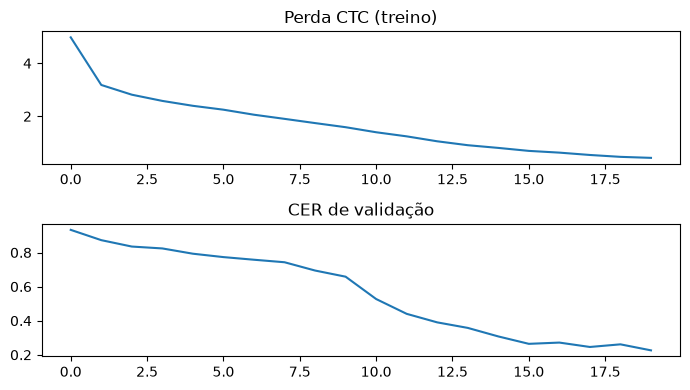

In [5]:
pred = m.prever_texto(modelo, te[0])
cer_te = m.micro_cer(te[1], pred)
print(f'CER teste (micro): {cer_te:.3f} | palavras exatas: {np.mean([p == r for p, r in zip(pred, te[1])]):.3f}')
fig, ax = plt.subplots(2, 1, figsize=(7, 4))
ax[0].plot([h['perda'] for h in hist]); ax[0].set_title('Perda CTC (treino)')
if 'cer_val' in hist[0]: ax[1].plot([h['cer_val'] for h in hist]); ax[1].set_title('CER de validação')
plt.tight_layout(); plt.savefig(SAIDA/'curvas.png', dpi=130); plt.show()

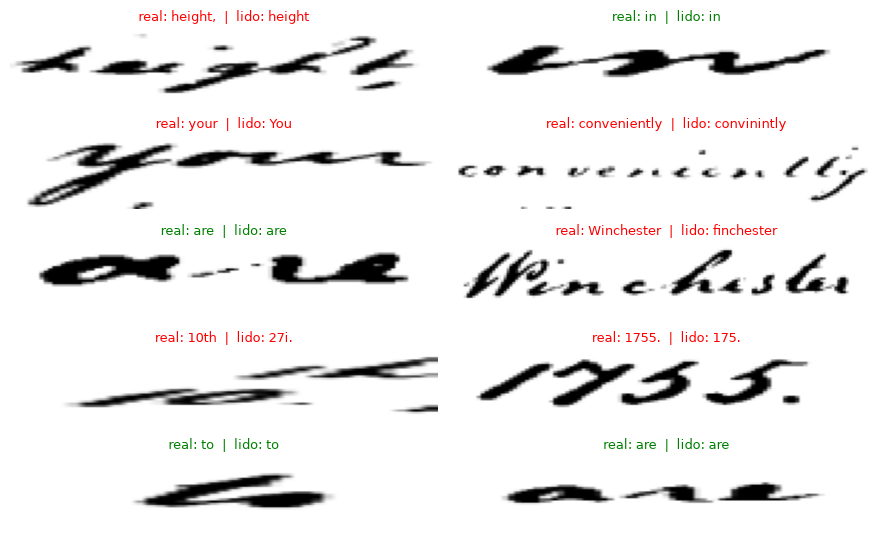

In [6]:
idx = np.random.default_rng(SEED).choice(len(te[0]), 10, replace=False)
fig, ax = plt.subplots(5, 2, figsize=(9, 5.5))
for a, i in zip(ax.ravel(), idx):
    a.imshow(te[0][i], cmap='gray_r', aspect='auto'); a.axis('off')
    a.set_title(f'real: {te[1][i]}  |  lido: {pred[i]}', fontsize=9, color='green' if pred[i] == te[1][i] else 'red')
plt.tight_layout(); plt.savefig(SAIDA/'exemplos.png', dpi=130); plt.show()

**Leitura:** diferentemente dos NB-06 a 09, o modelo escreve **qualquer** palavra, não escolhe de uma lista. Com ~3,4 mil palavras e poucas épocas o CER ainda é alto; o CRNN do TCC (Cap. 4) usa milhares de linhas e GPU. O objetivo aqui é o mecanismo: CNN → BiLSTM → CTC.